**Linear Regression**

In [17]:
import numpy as np

X=np.array([1,2,3,4,5,6,7,8])
y=np.array([2.1,3.9,4.2,6.1,6.8,8.3,8.9,10.4])

w,b,lr = 0.0,0.0,0.02

for epoch in range(1000):
    y_pred=w*X+b                  # Model Prediction
    error=y_pred-y
    mse=np.mean((error)**2)       # MSE loss function
    dw=2*np.mean(error*X)         # Calculate Gradients
    db=2*np.mean(error)
    w=w-lr*dw                     # Update parameters
    b=b-lr*db

print(w,b)
print(mse)
print(np.round(y_pred,2))

1.1441036890421807 1.188970471542414
0.08590775889109498
[ 2.33  3.48  4.62  5.77  6.91  8.05  9.2  10.34]


In [18]:
a=9
y_pred=w*a+b
print(y_pred)

11.48590367292204


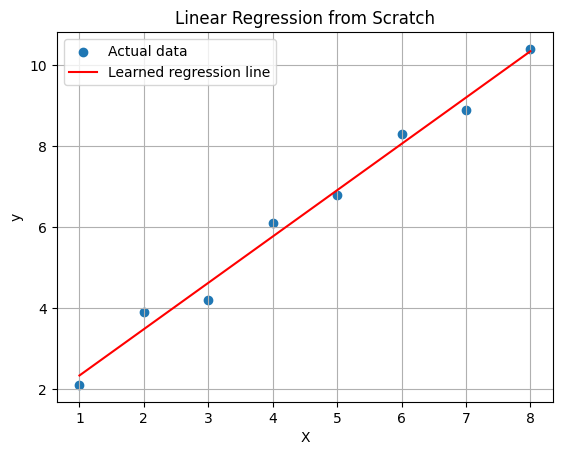

In [19]:
import matplotlib.pyplot as plt

y_pred=w*X +b

plt.scatter(X,y,label="Actual data")
plt.plot(X,y_pred,color="red",label="Learned regression line")

plt.xlabel("X")
plt.ylabel("y")
plt.title("Linear Regression from Scratch")
plt.legend()
plt.grid(True)
plt.show()

**Logistic Regression**

In [20]:
import numpy as np
X=np.array([100, 300, 700, 900], dtype=float)
y=np.array([0, 0, 1, 1], dtype=float)

# Scale transaction amounts
X=X/1000

w,b,lr=0.0,0.0,0.1
print("Scaled X:",X)

for epoch in range(5000):
    def sigmoid(z):                                    # Model Prediction
        return 1/(1+np.exp(-z))
    z=w*X+b
    p=sigmoid(z)
    L=-np.mean(y*np.log(p)+(1-y)*np.log(1-p))          # BCE loss function
    dw=np.mean(X*(p-y))                                # Calculate Gradients
    db=np.mean(p-y)
    w=w-lr*dw                                          # Update parameters
    b=b-lr*db

print(w,b)
print(L)
print(np.round(p,2))

Scaled X: [0.1 0.3 0.7 0.9]
11.90025460506686 -5.854763641162466
0.04872328369615919
[0.01 0.09 0.92 0.99]


In [21]:
# Predict for a new transaction of 500
amount=500/1000
probability=sigmoid(w*amount+b)
prediction=1 if probability>0.5 else 0
print(probability)
print(prediction)

0.523822863865845
1


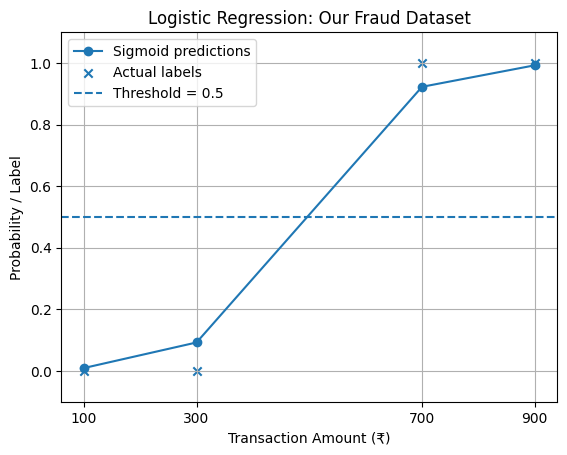

In [22]:
import matplotlib.pyplot as plt
import numpy as np

# Our original transaction amounts and labels
X = np.array([100, 300, 700, 900], dtype=float)
y = np.array([0, 0, 1, 1], dtype=float)

# Scale using the same method as training
X_scaled=X/1000

# Calculate sigmoid probabilities using our trained parameters
z=w*X_scaled+b
p=sigmoid(z)

# Plot our four transactions
plt.plot(X, p, marker='o', label='Sigmoid predictions')
plt.scatter(X, y, marker='x', label='Actual labels')

plt.axhline(y=0.5, linestyle='--', label='Threshold = 0.5')
plt.xlabel('Transaction Amount (₹)')
plt.ylabel('Probability / Label')
plt.title('Logistic Regression: Our Fraud Dataset')
plt.xticks(X)
plt.ylim(-0.1, 1.1)
plt.grid(True)
plt.legend()
plt.show()

**KNN (K Nearest Neighbours)**

In [23]:
import numpy as np

# Training features (study hours,sleep hours)
X=np.array([
    [1,7],
    [2,6],
    [3,7],
    [6,8],
    [7,6]
])
# Labels (fail:0,pass:1)
y=np.array([0,0,1,1,1])

# New student
new_student=np.array([4,7])
k=3

# 1:Euclidean distance
distances=[]
for point in X:
    distance=np.sqrt(np.sum((point-new_student) ** 2))
    distances.append(distance)

distances=np.array(distances)
print("Distances:",np.round(distances,3))

# 2:Find indices of the k nearest neighbors
nearest_indices=np.argsort(distances)[:k]

print("Nearest neighbors:",nearest_indices)
print("Nearest neighbor labels:",y[nearest_indices])

# 3: Majority voting
nearest_labels=y[nearest_indices]
counts=np.bincount(nearest_labels.astype(int))
prediction=np.argmax(counts)

# 4: Prediction
print("Prediction:",prediction)
if prediction==1:
    print("Result:Pass")
else:
    print("Result:Fail")

Distances: [3.    2.236 1.    2.236 3.162]
Nearest neighbors: [2 1 3]
Nearest neighbor labels: [1 0 1]
Prediction: 1
Result:Pass


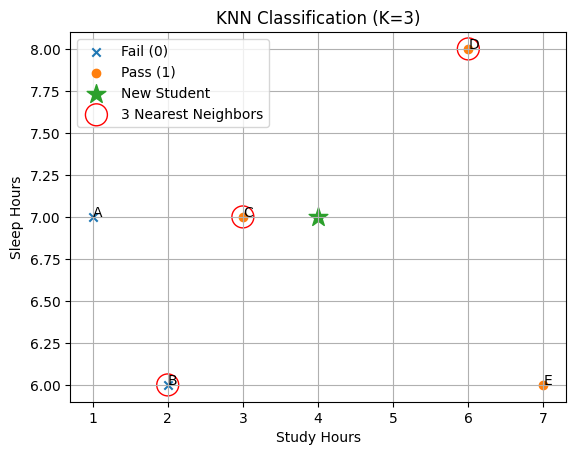

In [24]:
import numpy as np
import matplotlib.pyplot as plt

X = np.array([[1,7], [2,6], [3,7], [6,8], [7,6]])
y = np.array([0,0,1,1,1])
new = np.array([4,7])

# Plot Fail and Pass students
plt.scatter(X[y==0, 0], X[y==0, 1], marker="x", label="Fail (0)")
plt.scatter(X[y==1, 0], X[y==1, 1], marker="o", label="Pass (1)")

# Plot new student
plt.scatter(new[0], new[1], marker="*", s=200, label="New Student")

# Highlight the 3 nearest neighbors: B, C, D
nearest = [1, 2, 3]
plt.scatter(X[nearest, 0], X[nearest, 1],
            facecolors="none", edgecolors="red",
            s=250, label="3 Nearest Neighbors")

# Label each student
for i, name in enumerate(["A", "B", "C", "D", "E"]):
    plt.annotate(name, X[i])

plt.xlabel("Study Hours")
plt.ylabel("Sleep Hours")
plt.title("KNN Classification (K=3)")
plt.grid(True)
plt.legend()
plt.show()

**Decision Tree**

In [25]:
import numpy as np
data = [
    ["Sunny",    "Hot",  "High",   "Weak",   "No"],
    ["Sunny",    "Hot",  "High",   "Strong", "No"],
    ["Overcast", "Hot",  "High",   "Weak",   "Yes"],
    ["Rainy",    "Mild", "High",   "Weak",   "Yes"],
    ["Rainy",    "Cool", "Normal", "Weak",   "Yes"],
    ["Rainy",    "Cool", "Normal", "Strong", "No"],
    ["Overcast", "Cool", "Normal", "Strong", "Yes"],
    ["Sunny",    "Mild", "High",   "Weak",   "No"],
    ["Sunny",    "Cool", "Normal", "Weak",   "Yes"],
    ["Rainy",    "Mild", "Normal", "Weak",   "Yes"],
    ["Sunny",    "Mild", "Normal", "Strong", "Yes"],
    ["Overcast", "Mild", "High",   "Strong", "Yes"],
    ["Overcast", "Hot",  "Normal", "Weak",   "Yes"],
    ["Rainy",    "Mild", "High",   "Strong", "No"]
]

features=["Outlook","Temperature","Humidity","Windy"]
data=np.array(data,dtype=object)

# 1) Calculate entropy
def entropy(labels):
    _,counts=np.unique(labels,return_counts=True)
    probabilities=counts/len(labels)
    return -np.sum(probabilities*np.log2(probabilities))

# 2) Calculate information gain
def information_gain(data,feature_index):
    parent_entropy=entropy(data[:, -1])
    weighted_entropy=0
    values,counts=np.unique(
        data[:,feature_index],return_counts=True
    )
    for value,count in zip(values,counts):
        subset=data[data[:,feature_index]==value]
        weighted_entropy+=(count/len(data))*entropy(subset[:,-1])
    return parent_entropy-weighted_entropy

# 3) Calculate root information gains
print("Parent Entropy:",round(entropy(data[:,-1]),3))
print("\nInformation Gain:")
for i,feature in enumerate(features):
    print(feature,":",round(information_gain(data,i),3))

# 4) Build the ID3 decision tree recursively
def id3(data, available_features):
    labels=data[:,-1]
    values,counts=np.unique(labels,return_counts=True)

    # If all examples have the same target, return the answer
    if len(values)==1:
        return values[0]

    # If no features remain, return the majority class
    if len(available_features)==0:
        return values[np.argmax(counts)]

    # Choose the feature with maximum information gain
    gains=[
        information_gain(data,i)
        for i in available_features
    ]
    best_position=np.argmax(gains)
    best_index=available_features[best_position]
    best_feature=features[best_index]
    tree={best_feature:{}}

    # Create a branch for every value of the chosen feature
    for value in np.unique(data[:,best_index]):
        subset=data[data[:,best_index]==value]
        remaining_features=[
            i for i in available_features if i!=best_index
        ]
        tree[best_feature][value]=id3(
            subset,remaining_features
        )
    return tree

tree = id3(data, list(range(len(features))))
print("\nFinal Decision Tree:")
print(tree)


Parent Entropy: 0.94

Information Gain:
Outlook : 0.247
Temperature : 0.029
Humidity : 0.152
Windy : 0.048

Final Decision Tree:
{'Outlook': {'Overcast': 'Yes', 'Rainy': {'Windy': {'Strong': 'No', 'Weak': 'Yes'}}, 'Sunny': {'Humidity': {'High': 'No', 'Normal': 'Yes'}}}}


**Random Forest**

In [26]:
import numpy as np

# 1. Play Tennis dataset
data = np.array([
    ["Sunny",    "Hot",  "High",   "Weak",   "No"],
    ["Sunny",    "Hot",  "High",   "Strong", "No"],
    ["Overcast", "Hot",  "High",   "Weak",   "Yes"],
    ["Rainy",    "Mild", "High",   "Weak",   "Yes"],
    ["Rainy",    "Cool", "Normal", "Weak",   "Yes"],
    ["Rainy",    "Cool", "Normal", "Strong", "No"],
    ["Overcast", "Cool", "Normal", "Strong", "Yes"],
    ["Sunny",    "Mild", "High",   "Weak",   "No"],
    ["Sunny",    "Cool", "Normal", "Weak",   "Yes"],
    ["Rainy",    "Mild", "Normal", "Weak",   "Yes"],
    ["Sunny",    "Mild", "Normal", "Strong", "Yes"],
    ["Overcast", "Mild", "High",   "Strong", "Yes"],
    ["Overcast", "Hot",  "Normal", "Weak",   "Yes"],
    ["Rainy",    "Mild", "High",   "Strong", "No"]
], dtype=object)

features = ["Outlook", "Temperature", "Humidity", "Windy"]
X = data[:, :-1]
y = data[:, -1]


# 2. Calculate Entropy
def entropy(labels):
    _, counts=np.unique(labels, return_counts=True)
    probabilities=counts/len(labels)
    return -np.sum(probabilities*np.log2(probabilities))


# 3. Calculate Information Gain
def information_gain(X, y, feature_index):
    parent_entropy=entropy(y)
    weighted_entropy=0

    for value in np.unique(X[:, feature_index]):
        mask = X[:, feature_index]==value
        subset_y=y[mask]

        weighted_entropy += (
            len(subset_y)/len(y)
        )*entropy(subset_y)

    return parent_entropy-weighted_entropy

# 4. Build a Decision Tree
def build_tree(X, y, available_features, max_features, rng):

    # Stop if all labels are identical
    if len(np.unique(y))==1:
        return y[0]

    # If no features remain, return majority class
    if len(available_features)==0:
        values,counts=np.unique(y, return_counts=True)
        return values[np.argmax(counts)]

    # Randomly select features for this split
    selected_count=min(max_features, len(available_features))

    selected_features=rng.choice(
        available_features,
        size=selected_count,
        replace=False
    )

    # Select feature with maximum information gain
    gains = [
        information_gain(X, y, f)
        for f in selected_features
    ]

    best_feature=int(selected_features[np.argmax(gains)])

    # Majority class for unseen feature values
    values, counts=np.unique(y, return_counts=True)
    majority_class=values[np.argmax(counts)]

    tree = {
        "feature": best_feature,
        "majority": majority_class,
        "branches": {}
    }

    remaining_features = [
        f for f in available_features
        if f!=best_feature
    ]

    # Build a branch for each feature value
    for value in np.unique(X[:, best_feature]):
        mask = X[:, best_feature]==value

        tree["branches"][value]=build_tree(
            X[mask],
            y[mask],
            remaining_features,
            max_features,
            rng
        )
    return tree


# 5. Bootstrap Sampling
def bootstrap_sample(X, y, rng):
    n=len(X)

    indices=rng.choice(
        n,
        size=n,
        replace=True
    )

    return X[indices], y[indices]


# 6. Train Random Forest
def train_random_forest(X, y, n_trees=5, max_features=2, seed=42):
    rng=np.random.default_rng(seed)
    forest=[]

    for _ in range(n_trees):
        # Bootstrap sample
        X_sample, y_sample=bootstrap_sample(X, y, rng)

        # Train tree with random feature selection
        tree=build_tree(
            X_sample,
            y_sample,
            list(range(X.shape[1])),
            max_features,
            rng
        )

        forest.append(tree)

    return forest


# 7. Predict Using One Tree
def predict_tree(tree, sample):
    # Leaf node
    if not isinstance(tree, dict):
        return tree

    feature_index=tree["feature"]
    feature_value=sample[feature_index]

    # Fallback for unseen values
    if feature_value not in tree["branches"]:
        return tree["majority"]

    return predict_tree(
        tree["branches"][feature_value],
        sample
    )


# 8. Predict Using the Forest
def predict_forest(forest, sample):
    predictions=[
        predict_tree(tree, sample)
        for tree in forest
    ]

    values, counts=np.unique(
        predictions,
        return_counts=True
    )
    final_prediction = values[np.argmax(counts)]
    return final_prediction, predictions

# 9. Test input
new_sample = np.array(
    ["Sunny", "Cool", "High", "Strong"],
    dtype=object
)


# 10. Find a seed producing 3 Yes and 2 No votes
found=False

for seed in range(1000):
    forest=train_random_forest(
        X,
        y,
        n_trees=5,
        max_features=2,
        seed=seed
    )
    final_prediction, tree_predictions = predict_forest(
        forest,
        new_sample
    )
    no_count=sum(p=="No" for p in tree_predictions)
    yes_count=sum(p=="Yes" for p in tree_predictions)

    if yes_count>=3 and no_count>=2:
        print("Random seed:",seed)
        print("Number of trees:", len(forest))
        print("Individual tree predictions:", tree_predictions)
        print("Yes votes:", yes_count)
        print("No votes:", no_count)
        print("Final Random Forest prediction:", final_prediction)

        found=True
        break

if not found:
    print("No matching seed found in the search range.")


Random seed: 3
Number of trees: 5
Individual tree predictions: ['Yes', 'No', 'Yes', 'Yes', 'No']
Yes votes: 3
No votes: 2
Final Random Forest prediction: Yes


**Support Vector Machine (SVM)**

Learned weights: [-1.05563847e+00  6.76044577e-04]
Learned bias: 3.1599999999999766
Decision scores: [ 1.05   1.051 -1.061 -1.06 ]
Predictions: [ 1  1 -1 -1]
Actual labels: [ 1  1 -1 -1]
Margin on each side: 0.947
Total margin width: 1.895


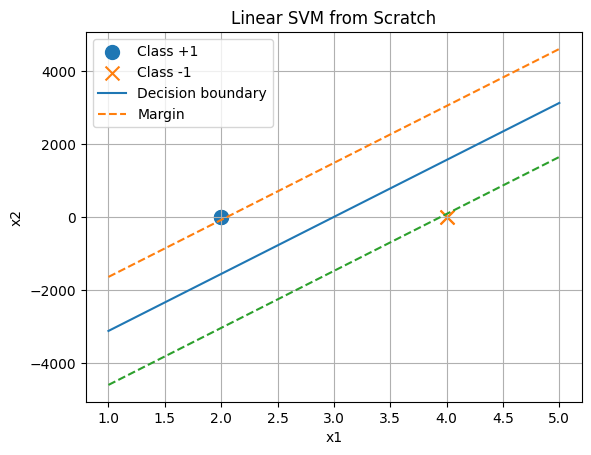

In [27]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Training data
X = np.array([
    [2, 2],
    [2, 4],
    [4, 2],
    [4, 4]
], dtype=float)

y = np.array([1, 1, -1, -1], dtype=float)

# 2. Initialize parameters
w = np.zeros(X.shape[1])
b = 0.0

learning_rate = 0.01
lambda_param = 0.01
epochs = 5000

# 3. Train Linear SVM using hinge loss
for epoch in range(epochs):
    for i in range(len(X)):
        condition = y[i] * (np.dot(X[i], w) + b)

        if condition >= 1:
            # Correctly classified and outside the margin
            w = w - learning_rate * (2 * lambda_param * w)
        else:
            # Misclassified or inside the margin
            w = w - learning_rate * (
                2 * lambda_param * w - y[i] * X[i]
            )
            b = b + learning_rate * y[i]

# 4. Display learned parameters
print("Learned weights:", w)
print("Learned bias:", b)

# 5. Predict the training points
scores = X @ w + b
predictions = np.where(scores >= 0, 1, -1)

print("Decision scores:", np.round(scores, 3))
print("Predictions:", predictions)
print("Actual labels:", y.astype(int))

# 6. Calculate margin width
weight_norm = np.linalg.norm(w)

if weight_norm > 0:
    print("Margin on each side:", round(1 / weight_norm, 3))
    print("Total margin width:", round(2 / weight_norm, 3))

# 7. Plot data and decision boundary
plt.scatter(X[y == 1, 0], X[y == 1, 1],
            marker="o", s=100, label="Class +1")
plt.scatter(X[y == -1, 0], X[y == -1, 1],
            marker="x", s=100, label="Class -1")

if abs(w[1]) > 1e-10:
    x1 = np.linspace(1, 5, 100)
    boundary = -(w[0] * x1 + b) / w[1]
    margin_positive = (1 - w[0] * x1 - b) / w[1]
    margin_negative = (-1 - w[0] * x1 - b) / w[1]

    plt.plot(x1, boundary, label="Decision boundary")
    plt.plot(x1, margin_positive, "--", label="Margin")
    plt.plot(x1, margin_negative, "--")
else:
    # Vertical boundary when w[1] = 0
    boundary_x = -b / w[0]
    plt.axvline(boundary_x, label="Decision boundary")

    margin_1 = (-1 - b) / w[0]
    margin_2 = (1 - b) / w[0]
    plt.axvline(margin_1, linestyle="--", label="Margin")
    plt.axvline(margin_2, linestyle="--")

plt.xlabel("x1")
plt.ylabel("x2")
plt.title("Linear SVM from Scratch")
plt.grid(True)
plt.legend()
plt.show()

**Naive Bayes**

In [28]:

import numpy as np

# 1. Dataset: Weather, Car, Class
data = np.array([
    ["Sunny", "Working", "Go Out"],
    ["Sunny", "Working", "Go Out"],
    ["Sunny", "Working", "Go Out"],
    ["Rainy", "Broken", "Stay Home"],
    ["Rainy", "Broken", "Stay Home"]
], dtype=object)

X = data[:, :2]
y = data[:, 2]

# 2. New observation to classify
new_sample = ["Sunny", "Working"]

# 3. Calculate prior probabilities
classes, class_counts = np.unique(y, return_counts=True)

priors = {}

for cls, count in zip(classes, class_counts):
    priors[cls] = count / len(y)

print("Prior probabilities:")
for cls in classes:
    print(f"P({cls}) = {priors[cls]:.2f}")

# 4. Calculate conditional probabilities
conditional_probs = {}

for cls in classes:
    conditional_probs[cls] = {}

    X_class = X[y == cls]

    for feature_index, feature_name in enumerate(
        ["Weather", "Car"]
    ):
        conditional_probs[cls][feature_name] = {}

        possible_values = np.unique(X[:, feature_index])

        for value in possible_values:
            count = np.sum(X_class[:, feature_index] == value)
            probability = count / len(X_class)

            conditional_probs[cls][feature_name][value] = probability

print("\nConditional probabilities:")

for cls in classes:
    print(f"\nClass: {cls}")

    for feature_name in ["Weather", "Car"]:
        for value, probability in conditional_probs[cls][feature_name].items():
            print(f"P({value} | {cls}) = {probability:.2f}")

# 5. Calculate Naive Bayes scores
scores = {}

for cls in classes:
    score = priors[cls]

    for feature_index, feature_name in enumerate(
        ["Weather", "Car"]
    ):
        value = new_sample[feature_index]

        probability = conditional_probs[cls][feature_name][value]
        score *= probability

    scores[cls] = score

print("\nClass scores:")

for cls in classes:
    print(f"Score({cls}) = {scores[cls]:.2f}")

# 6. Predict the class with the highest score
prediction = max(scores, key=scores.get)

print("\nNew observation:", new_sample)
print("Predicted class:", prediction)


Prior probabilities:
P(Go Out) = 0.60
P(Stay Home) = 0.40

Conditional probabilities:

Class: Go Out
P(Rainy | Go Out) = 0.00
P(Sunny | Go Out) = 1.00
P(Broken | Go Out) = 0.00
P(Working | Go Out) = 1.00

Class: Stay Home
P(Rainy | Stay Home) = 1.00
P(Sunny | Stay Home) = 0.00
P(Broken | Stay Home) = 1.00
P(Working | Stay Home) = 0.00

Class scores:
Score(Go Out) = 0.60
Score(Stay Home) = 0.00

New observation: ['Sunny', 'Working']
Predicted class: Go Out


**K-Means CLustering**


========== ITERATION 1 ==========

Distances and cluster assignments:
A1 [ 2. 10.] -> distances [0.   3.61 8.06], Cluster 1
A2 [2. 5.] -> distances [5.   4.24 3.16], Cluster 3
A3 [8. 4.] -> distances [8.49 5.   7.28], Cluster 2
B1 [5. 8.] -> distances [3.61 0.   7.21], Cluster 2
B2 [7. 5.] -> distances [7.07 3.61 6.71], Cluster 2
B3 [6. 4.] -> distances [7.21 4.12 5.39], Cluster 2
C1 [1. 2.] -> distances [8.06 7.21 0.  ], Cluster 3
C2 [4. 9.] -> distances [2.24 1.41 7.62], Cluster 2

Updated centroids:
Centroid 1: [ 2. 10.]
Centroid 2: [6. 6.]
Centroid 3: [1.5 3.5]

========== ITERATION 2 ==========

Distances and cluster assignments:
A1 [ 2. 10.] -> distances [0.   5.66 6.52], Cluster 1
A2 [2. 5.] -> distances [5.   4.12 1.58], Cluster 3
A3 [8. 4.] -> distances [8.49 2.83 6.52], Cluster 2
B1 [5. 8.] -> distances [3.61 2.24 5.7 ], Cluster 2
B2 [7. 5.] -> distances [7.07 1.41 5.7 ], Cluster 2
B3 [6. 4.] -> distances [7.21 2.   4.53], Cluster 2
C1 [1. 2.] -> distances [8.06 6.4  1.58], 

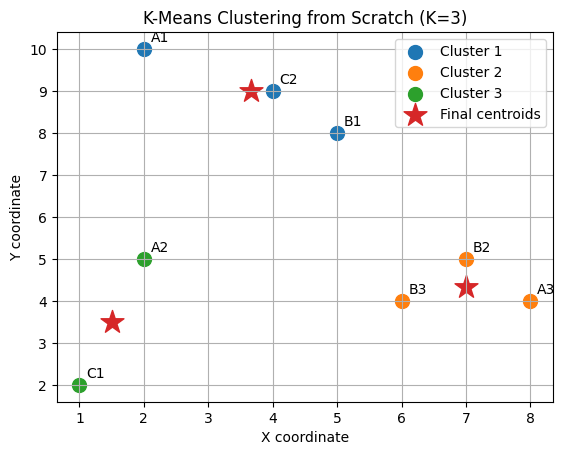

In [29]:

import numpy as np
import matplotlib.pyplot as plt

# 1. Given data points from our PDF
X = np.array([
    [2, 10],  # A1
    [2, 5],   # A2
    [8, 4],   # A3
    [5, 8],   # B1
    [7, 5],   # B2
    [6, 4],   # B3
    [1, 2],   # C1
    [4, 9]    # C2
], dtype=float)

labels = ["A1", "A2", "A3", "B1", "B2", "B3", "C1", "C2"]

# 2. Initial centroids: A1, B1, C1
centroids = np.array([
    [2, 10],
    [5, 8],
    [1, 2]
], dtype=float)

K = 3
max_iterations = 100

# 3. K-Means algorithm
for iteration in range(max_iterations):

    # Calculate distance from each point to every centroid
    distances = np.sqrt(
        np.sum((X[:, np.newaxis, :] - centroids[np.newaxis, :, :])**2, axis=2)
    )

    # Assign each point to the nearest centroid
    clusters = np.argmin(distances, axis=1)

    print(f"\n========== ITERATION {iteration + 1} ==========")

    print("\nDistances and cluster assignments:")
    for i in range(len(X)):
        distance_text = np.round(distances[i], 2)
        print(f"{labels[i]} {X[i]} -> distances {distance_text}, Cluster {clusters[i] + 1}")

    # Calculate updated centroids
    new_centroids = np.zeros_like(centroids)

    for cluster_id in range(K):
        cluster_points = X[clusters == cluster_id]

        if len(cluster_points) > 0:
            new_centroids[cluster_id] = np.mean(cluster_points, axis=0)
        else:
            # Keep the old centroid if a cluster is empty
            new_centroids[cluster_id] = centroids[cluster_id]

    print("\nUpdated centroids:")
    for cluster_id, centroid in enumerate(new_centroids):
        print(f"Centroid {cluster_id + 1}: {centroid}")

    # Stop if centroids no longer change
    if np.allclose(centroids, new_centroids):
        centroids = new_centroids
        print("\nConverged! Centroids no longer change.")
        break

    centroids = new_centroids


# 4. Final cluster assignments
print("\n========== FINAL CLUSTERS ==========")

for cluster_id in range(K):
    cluster_points = X[clusters == cluster_id]
    cluster_labels = [
        labels[i] for i in range(len(X))
        if clusters[i] == cluster_id
    ]

    print(f"Cluster {cluster_id + 1}: {cluster_labels}")
    print(f"Final centroid: {centroids[cluster_id]}")


# 5. Plot the final clusters
for cluster_id in range(K):
    points = X[clusters == cluster_id]

    if len(points) > 0:
        plt.scatter(
            points[:, 0],
            points[:, 1],
            s=100,
            label=f"Cluster {cluster_id + 1}"
        )

        for i in range(len(X)):
            if clusters[i] == cluster_id:
                plt.annotate(labels[i], X[i], xytext=(5, 5),
                             textcoords="offset points")

plt.scatter(
    centroids[:, 0],
    centroids[:, 1],
    marker="*",
    s=300,
    label="Final centroids"
)

plt.xlabel("X coordinate")
plt.ylabel("Y coordinate")
plt.title("K-Means Clustering from Scratch (K=3)")
plt.grid(True)
plt.legend()
plt.show()


**Principal Component Analysis (PCA)**

Original Dataset:
 [[2. 1.]
 [3. 2.]
 [4. 3.]
 [5. 4.]]

Mean: [3.5 2.5]

Centered Data:
 [[-1.5 -1.5]
 [-0.5 -0.5]
 [ 0.5  0.5]
 [ 1.5  1.5]]

Covariance Matrix:
 [[1.66666667 1.66666667]
 [1.66666667 1.66666667]]

Eigenvalues:
 [3.33333333 0.        ]

Eigenvectors:
 [[ 0.70710678 -0.70710678]
 [ 0.70710678  0.70710678]]

First Principal Component:
 [0.70710678 0.70710678]

PC1 Values:
 [-2.1213 -0.7071  0.7071  2.1213]

Explained Variance Ratios:
 [1. 0.]

PC1 Explained Variance: 100.0 %


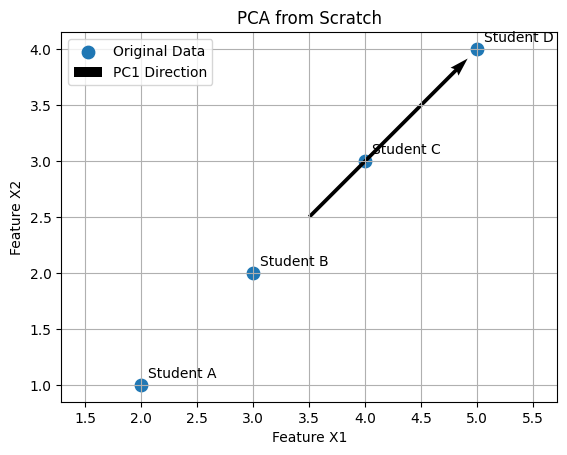

In [30]:

import numpy as np
import matplotlib.pyplot as plt

# Step 1: Dataset (4 students, 2 features)
X = np.array([
    [2, 1],
    [3, 2],
    [4, 3],
    [5, 4]
], dtype=float)

print("Original Dataset:\n", X)

# Step 2: Calculate mean and center the data
mean = np.mean(X, axis=0)
X_centered = X - mean

print("\nMean:", mean)
print("\nCentered Data:\n", X_centered)

# Step 3: Calculate sample covariance matrix
C = np.cov(X_centered, rowvar=False, ddof=1)

print("\nCovariance Matrix:\n", C)

# Step 4: Calculate eigenvalues and eigenvectors
eigenvalues, eigenvectors = np.linalg.eigh(C)

# Sort in descending order of eigenvalues
indices = np.argsort(eigenvalues)[::-1]
eigenvalues = eigenvalues[indices]
eigenvectors = eigenvectors[:, indices]

print("\nEigenvalues:\n", eigenvalues)
print("\nEigenvectors:\n", eigenvectors)

# Step 5: Select the first principal component
pc1 = eigenvectors[:, 0]

print("\nFirst Principal Component:\n", pc1)

# Step 6: Project centered data onto PC1
Z = X_centered @ pc1

print("\nPC1 Values:\n", np.round(Z, 4))

# Step 7: Calculate explained variance ratio
explained_variance_ratio = (
    eigenvalues / np.sum(eigenvalues)
)

print("\nExplained Variance Ratios:\n",
      np.round(explained_variance_ratio, 4))

print("\nPC1 Explained Variance:",
      round(explained_variance_ratio[0] * 100, 2), "%")

# Step 8: Visualize original data and PC1 direction
plt.scatter(X[:, 0], X[:, 1], s=80, label="Original Data")

for i, point in enumerate(X):
    plt.annotate(
        f"Student {'ABCD'[i]}",
        (point[0], point[1]),
        xytext=(5, 5),
        textcoords="offset points"
    )

# Draw the PC1 direction through the mean
direction = pc1 * 2
plt.quiver(
    mean[0], mean[1],
    direction[0], direction[1],
    angles="xy", scale_units="xy", scale=1,
    label="PC1 Direction"
)

plt.xlabel("Feature X1")
plt.ylabel("Feature X2")
plt.title("PCA from Scratch")
plt.grid(True)
plt.axis("equal")
plt.legend()
plt.show()


**XGBoost**

In [31]:

import numpy as np

# Dataset: Study hours -> Actual scores
X = np.array([[1], [2], [3], [4]], dtype=float)
y = np.array([30, 40, 50, 60], dtype=float)

# Hyperparameters
learning_rate = 0.5
n_estimators = 3
max_depth = 1
lambda_reg = 1.0  # L2 regularization

# Initial prediction: mean of target values
base_prediction = np.mean(y)
predictions = np.full(len(y), base_prediction)

print("Initial prediction:", base_prediction)
print("\nInitial predictions:", predictions)


# A tiny regression tree trained using XGBoost-style
# gradient and Hessian split gain for squared error.
def build_tree(X, gradients, hessians, depth=0):
    G = np.sum(gradients)
    H = np.sum(hessians)

    # Optimal leaf value with L2 regularization
    leaf_value = -G / (H + lambda_reg)

    # Stop if maximum depth is reached
    if depth >= max_depth or len(X) < 2:
        return {"leaf": leaf_value}

    best_gain = 0
    best_split = None

    # Try splits between sorted unique feature values
    for feature in range(X.shape[1]):
        values = np.unique(X[:, feature])
        thresholds = (values[:-1] + values[1:]) / 2

        for threshold in thresholds:
            left_mask = X[:, feature] <= threshold
            right_mask = ~left_mask

            if not np.any(left_mask) or not np.any(right_mask):
                continue

            GL = np.sum(gradients[left_mask])
            HL = np.sum(hessians[left_mask])
            GR = np.sum(gradients[right_mask])
            HR = np.sum(hessians[right_mask])

            # XGBoost split gain (gamma = 0)
            gain = 0.5 * (
                GL**2 / (HL + lambda_reg)
                + GR**2 / (HR + lambda_reg)
                - G**2 / (H + lambda_reg)
            )

            if gain > best_gain:
                best_gain = gain
                best_split = (feature, threshold, left_mask, right_mask)

    # Keep a single leaf if no split improves the objective
    if best_split is None:
        return {"leaf": leaf_value}

    feature, threshold, left_mask, right_mask = best_split

    return {
        "feature": feature,
        "threshold": threshold,
        "left": build_tree(
            X[left_mask], gradients[left_mask],
            hessians[left_mask], depth + 1
        ),
        "right": build_tree(
            X[right_mask], gradients[right_mask],
            hessians[right_mask], depth + 1
        )
    }


def predict_tree(tree, row):
    if "leaf" in tree:
        return tree["leaf"]

    feature = tree["feature"]
    threshold = tree["threshold"]

    if row[feature] <= threshold:
        return predict_tree(tree["left"], row)

    return predict_tree(tree["right"], row)


trees = []

for iteration in range(n_estimators):
    # For squared error loss:
    # gradient = prediction - actual
    # Hessian = 1
    gradients = predictions - y
    hessians = np.ones(len(y))

    tree = build_tree(X, gradients, hessians)
    trees.append(tree)

    # Each tree adds a correction scaled by learning rate
    corrections = np.array([
        predict_tree(tree, row) for row in X
    ])

    predictions += learning_rate * corrections

    print(f"\nAfter tree {iteration + 1}:")
    print("Gradients:", gradients)
    print("Tree corrections:", np.round(corrections, 3))
    print("Updated predictions:", np.round(predictions, 3))
    print("MSE:", round(np.mean((y - predictions) ** 2), 3))

print("\nFinal predictions:", np.round(predictions, 3))


Initial prediction: 45.0

Initial predictions: [45. 45. 45. 45.]

After tree 1:
Gradients: [ 15.   5.  -5. -15.]
Tree corrections: [-6.667 -6.667  6.667  6.667]
Updated predictions: [41.667 41.667 48.333 48.333]
MSE: 69.444

After tree 2:
Gradients: [ 11.66666667   1.66666667  -1.66666667 -11.66666667]
Tree corrections: [-4.444 -4.444  4.444  4.444]
Updated predictions: [39.444 39.444 50.556 50.556]
MSE: 44.753

After tree 3:
Gradients: [ 9.44444444 -0.55555556  0.55555556 -9.44444444]
Tree corrections: [-4.722  2.361  2.361  2.361]
Updated predictions: [37.083 40.625 51.736 51.736]
MSE: 30.468

Final predictions: [37.083 40.625 51.736 51.736]
